# Scoring

Extraction performance (Table 4-equivalent) and end-to-end reconfiguration
performance (Table 2/3-equivalent), full grid -- every model x every
strategy, for every approach (ReIntent / ablation / direct LLM / CoT LLM).
Nothing is collapsed to a single "best" row; every table below is indexed
by (model, strategy) or (approach, model, strategy).

Writes every table to `eval/eval_outputs/*.csv` (+ a `.json` for the end-to-end
summary) and every figure to `eval/eval_outputs/*.png`.

In [1]:
import json
import math
import sys
from pathlib import Path

ROOT = Path.cwd().parent  # repo root, assuming this notebook runs from eval/
sys.path.insert(0, str(ROOT / "src"))
sys.path.insert(0, str(ROOT / "eval" / "system_model"))

import pandas as pd
import matplotlib.pyplot as plt

from agent.model.schemas import Requirement
from agent.utils.pipeline import check_candidate_placement, to_native_unit
from loader import load_flows, load_links, load_nodes, load_services

OUT_DIR = ROOT / "eval" / "eval_outputs"
OUT_DIR.mkdir(parents=True, exist_ok=True)
plt.style.use("seaborn-v0_8-whitegrid")

KPI_REMAP = {"e2e_latency": "latency"}
VALUE_REL_TOL = 0.01
# Synonyms used in v3's more varied natural-language intent writing that
# to_native_unit's own dicts don't recognize -- confirmed these never appear
# as the MODEL's own extraction `unit` (always normalized there), so this is
# purely a scoring-side gap, not a live pipeline bug.
_UNIT_SYNONYMS = {"vCPUs": "vCPU", "virtual cores": "virtual CPUs", "gigabytes": "GB", "megabytes": "MB"}

MODEL_FILE_TAG = {
    "gemini-2.5-flash-lite": "google-gemini-2.5-flash-lite",
    "gpt-oss-120b": "openai-gpt-oss-120b",
    "gpt-oss-20b": "openai-gpt-oss-20b",
    "llama-3.3-70b": "meta-llama-llama-3.3-70b-instruct",
    "mistral-small-3.2-24b": "mistralai-mistral-small-3.2-24b-instruct",
}
MODEL_ORDER = ["gemini-2.5-flash-lite", "gpt-oss-120b", "gpt-oss-20b", "llama-3.3-70b", "mistral-small-3.2-24b"]
MODEL_LABELS = {
    "gemini-2.5-flash-lite": "Gemini 2.5 Flash-Lite", "gpt-oss-120b": "GPT-OSS 120B",
    "gpt-oss-20b": "GPT-OSS 20B", "llama-3.3-70b": "Llama 3.3 70B", "mistral-small-3.2-24b": "Mistral Small 24B",
}
STRATEGY_ORDER = ["zero_shot", "one_shot", "few_shot"]
STRATEGY_LABELS = {"zero_shot": "Zero-shot", "one_shot": "One-shot", "few_shot": "Few-shot"}
STRATEGY_COLORS = {"zero_shot": "#3569A8", "one_shot": "#28A69A", "few_shot": "#E99A43"}
APPROACH_ORDER = ["pipeline", "ablation", "direct", "cot"]
APPROACH_LABELS = {"pipeline": "ReIntent (ours)", "ablation": "w/o Necessity Assessment",
                    "direct": "Direct LLM", "cot": "CoT LLM"}

MIDX = pd.MultiIndex.from_product([MODEL_ORDER, STRATEGY_ORDER], names=["model", "strategy"])

## Shared fixtures

Scenario system-model fixtures, the reference (true-optimum) migration counts, and the matching helpers reused across both the extraction and the end-to-end evaluation.

In [2]:
with open(ROOT / "eval" / "benchmark" / "scenarios.json") as f:
    SCENARIOS_BY_ID = {s["id"]: s for s in json.load(f)}
NODES = load_nodes()
LINKS = load_links()
_cache = {}


def scenario_fixtures(sid):
    if sid not in _cache:
        scenario = SCENARIOS_BY_ID[sid]
        services = load_services(scenario)
        flows = load_flows(scenario)
        gt_reqs = []
        for i, req in enumerate(scenario["requirements"]):
            kpi = KPI_REMAP.get(req["kpi_type"], req["kpi_type"])
            gt_reqs.append(Requirement(
                kpi_type=kpi, comparator=req["comparator"], target_value=req["new_value"],
                unit=req["unit"], target_type=req["target_type"], target_id=req["target_id"],
                source_span="", requirement_id=f"gt-{i}",
            ))
        bp = {sid2: s.current_node for sid2, s in services.items()}
        _cache[sid] = (services, flows, gt_reqs, bp, scenario["minimum_migrations"])
    return _cache[sid]


def full_placement(predicted_placement, baseline_placement):
    if predicted_placement is None:
        return dict(baseline_placement)
    return {sid: predicted_placement.get(sid, node) for sid, node in baseline_placement.items()}


ref_rows = []
with open(ROOT / "eval" / "results_reference" / "reference_decisions.jsonl") as fh:
    for line in fh:
        r = json.loads(line)
        ref_rows.append({"scenario_id": r["scenario_id"], "n_moved_ref": len(r["ref_moved"]),
                          "ref_decision": r["ref_decision"]})
ref_df = pd.DataFrame(ref_rows).set_index("scenario_id")
REF_LOOKUP = ref_df["n_moved_ref"]
# The deterministic reference (necessity checker + decision engine run
# directly on the scenario's ground-truth requirements, no LLM anywhere)
# is used as THE ground truth throughout this notebook -- not the
# benchmark's own embedded label -- because the research question is
# "does LLM extraction degrade the decision", which this isolates cleanly:
# the solver is identical on both sides of every comparison below, only
# the input (exact vs LLM-extracted requirements) differs. The two
# happen to agree on 500/500 decisions (see eval/run_reference_decision.py's
# own printed agreement rate) -- a cross-validation result, not a reason
# to treat them as interchangeable in principle.
REF_DECISION_LOOKUP = ref_df["ref_decision"]

In [3]:
def gt_requirements(record):
    out = []
    for req in record["ground_truth"]["requirements"]:
        kpi = KPI_REMAP.get(req["kpi_type"], req["kpi_type"])
        out.append({"target_id": req["target_id"], "kpi_type": kpi,
                     "comparator": req["comparator"], "value": req["new_value"]})
    return out


def match_requirements(gt_list, pred_list):
    """Returns (tp, fp, fn) -- a prediction matches a not-yet-matched ground
    truth entry on (target_id, kpi_type, comparator) and a value within 1%
    (absorbs float rounding from unit conversion, tight enough that a wrong
    digit still misses)."""
    matched_gt = set()
    tp = 0
    for p in pred_list:
        for i, g in enumerate(gt_list):
            if i in matched_gt:
                continue
            if (g["target_id"] == p["target_id"] and g["kpi_type"] == p["kpi_type"]
                    and g["comparator"] == p["comparator"]
                    and math.isclose(g["value"], p["value"], rel_tol=VALUE_REL_TOL, abs_tol=1e-6)):
                matched_gt.add(i)
                tp += 1
                break
    fp = len(pred_list) - tp
    fn = len(gt_list) - len(matched_gt)
    return tp, fp, fn


def extracted_to_canonical(req):
    return {"target_id": req["target_id"], "kpi_type": req["kpi_type"],
            "comparator": req["comparator"], "value": req["target_value"]}


def raw_to_canonical(req):
    native = to_native_unit(req["target_value"], req["unit"], req["kpi_type"])
    if native is None:
        return None
    return {"target_id": req["target_id"], "kpi_type": req["kpi_type"],
            "comparator": req["comparator"], "value": native}


def gt_requirements_from_mentions(record):
    """Ground truth at the *mention* level (intent_metadata, written by the
    intent generator) rather than the resolved-requirement level -- carries
    the explicitness `level` (L1 explicit ... L4 oblique) a resolved
    requirement doesn't."""
    out = []
    for m in record["intent_metadata"]["mentions"]:
        kpi = KPI_REMAP.get(m["kpi_type"], m["kpi_type"])
        unit = _UNIT_SYNONYMS.get(m["written_unit"], m["written_unit"])
        native = to_native_unit(float(m["written_value"]), unit, kpi)
        if native is None:
            continue
        out.append({"target_id": m["target_id"], "kpi_type": kpi, "comparator": m["comparator"],
                     "value": native, "level": m["level"]})
    return out


def match_requirements_detailed(gt_list, pred_list):
    """Same matching rule as match_requirements, but returns which gt_list
    entries matched (by index) -- needed to break recall down by `level`."""
    matched_gt = set()
    for p in pred_list:
        for i, g in enumerate(gt_list):
            if i in matched_gt:
                continue
            if (g["target_id"] == p["target_id"] and g["kpi_type"] == p["kpi_type"]
                    and g["comparator"] == p["comparator"]
                    and math.isclose(g["value"], p["value"], rel_tol=VALUE_REL_TOL, abs_tol=1e-6)):
                matched_gt.add(i)
                break
    return matched_gt

In [4]:
def pipeline_predicted_decision(record):
    necessity = record["necessity_result"]
    decision = record["decision_result"]
    if necessity is not None and necessity["status"] == "reconfiguration_not_required":
        return "STAY"
    if decision is None:
        return "STAY"
    if decision["outcome"] == "INFEASIBLE":
        return "INFEASIBLE"
    if not decision["decision"]:
        return "STAY"
    return "OFFLOAD"


def pipeline_final_configuration(record):
    if record["decision_result"] is not None:
        return record["decision_result"]["new_configuration"]
    return record["necessity_result"]["current_placement"]


def pipeline_token_usage(record):
    """Sum of both LLM calls' total_tokens -- extraction + explanation."""
    total = 0
    for key in ("extraction_token_usage", "explanation_token_usage"):
        usage = record.get(key)
        if usage:
            total += usage.get("total_tokens", 0)
    return total

## Loading records

Three sources, all 5 models x all 3 strategies:

- `eval/results/` -- the full ReIntent pipeline (extraction + necessity
  checker + decision engine + explanation). Scored for *both* extraction
  and end-to-end performance.
- `eval/results_ablation/` -- same pipeline, necessity checker skipped.
  End-to-end only (same extraction mechanism as the pipeline, not a
  separate thing to evaluate).
- `eval/baselines/results/` -- single-shot Direct LLM and CoT LLM
  baselines (no solver). End-to-end only.

In [5]:
print("Loading pipeline records (extraction + e2e)...")
extraction_rows = []
e2e_rows = []
for model, tag in MODEL_FILE_TAG.items():
    for strategy in STRATEGY_ORDER:
        pfile = sorted((ROOT / "eval" / "results").glob(f"{tag}__{strategy}__*.jsonl"))[-1]
        with open(pfile) as fh:
            for line in fh:
                r = json.loads(line)
                if "error" in r:
                    continue
                services, flows, gt_reqs, bp, min_migrations = scenario_fixtures(r["scenario_id"])

                # --- extraction ---
                gt = gt_requirements(r)
                pred_ext = [extracted_to_canonical(x) for x in r["extracted_requirements"]]
                tp_e, fp_e, fn_e = match_requirements(gt, pred_ext)
                pred_raw = [x for x in (raw_to_canonical(x) for x in r["extraction_raw"]) if x is not None]
                tp_r, fp_r, fn_r = match_requirements(gt, pred_raw)

                gt_m = gt_requirements_from_mentions(r)
                matched_raw_m = match_requirements_detailed(gt_m, pred_raw)
                for i, g in enumerate(gt_m):
                    extraction_rows.append({
                        "model": model, "strategy": strategy, "scenario_id": r["scenario_id"],
                        "level": g["level"], "matched": i in matched_raw_m,
                    })

                # --- e2e ---
                pred_decision = pipeline_predicted_decision(r)
                cfg = pipeline_final_configuration(r)
                pred_moved = frozenset(sid for sid, node in cfg.items() if node != bp[sid])
                gt_decision = REF_DECISION_LOOKUP[r["scenario_id"]]
                valid, _ = check_candidate_placement(cfg, services, NODES, LINKS, gt_reqs, flows)

                e2e_rows.append({
                    "approach": "pipeline", "model": model, "strategy": strategy,
                    "scenario_id": r["scenario_id"], "gt_decision": gt_decision,
                    "decision_correct": pred_decision == gt_decision,
                    "n_moved_pred": len(pred_moved), "real_valid": valid,
                    "elapsed_s": r.get("total_elapsed_s"), "total_tokens": pipeline_token_usage(r),
                    "tp_ext": tp_e, "fp_ext": fp_e, "fn_ext": fn_e,
                    "tp_raw": tp_r, "fp_raw": fp_r, "fn_raw": fn_r,
                    "exact_match_ext": fp_e == 0 and fn_e == 0, "exact_match_raw": fp_r == 0 and fn_r == 0,
                })

print(f"  {len(e2e_rows)} pipeline scenario-records, {len(extraction_rows)} requirement mentions")

Loading pipeline records (extraction + e2e)...


  7500 pipeline scenario-records, 15795 requirement mentions


In [6]:
print("Loading ablation records (e2e only)...")
for model, tag in MODEL_FILE_TAG.items():
    for strategy in STRATEGY_ORDER:
        afile = sorted((ROOT / "eval" / "results_ablation").glob(f"{tag}__{strategy}__*.jsonl"))[-1]
        with open(afile) as fh:
            for line in fh:
                r = json.loads(line)
                if "error" in r:
                    continue
                services, flows, gt_reqs, bp, _ = scenario_fixtures(r["scenario_id"])
                pred_decision = pipeline_predicted_decision(r)
                cfg = pipeline_final_configuration(r)
                pred_moved = frozenset(sid for sid, node in cfg.items() if node != bp[sid])
                gt_decision = REF_DECISION_LOOKUP[r["scenario_id"]]
                valid, _ = check_candidate_placement(cfg, services, NODES, LINKS, gt_reqs, flows)
                e2e_rows.append({
                    "approach": "ablation", "model": model, "strategy": strategy,
                    "scenario_id": r["scenario_id"], "gt_decision": gt_decision,
                    "decision_correct": pred_decision == gt_decision,
                    "n_moved_pred": len(pred_moved), "real_valid": valid,
                    "elapsed_s": r.get("total_elapsed_s"), "total_tokens": pipeline_token_usage(r),
                    "tp_ext": None, "fp_ext": None, "fn_ext": None,
                    "tp_raw": None, "fp_raw": None, "fn_raw": None,
                    "exact_match_ext": None, "exact_match_raw": None,
                })
print(f"  {len(e2e_rows)} total scenario-records after ablation")

Loading ablation records (e2e only)...


  15000 total scenario-records after ablation


In [7]:
print("Loading direct/cot baseline records (e2e only)...")
for approach in ("direct", "cot"):
    for model, tag in MODEL_FILE_TAG.items():
        for strategy in STRATEGY_ORDER:
            bfile = sorted((ROOT / "eval" / "baselines" / "results").glob(f"{approach}__{tag}__{strategy}__*.jsonl"))[-1]
            with open(bfile) as fh:
                for line in fh:
                    r = json.loads(line)
                    if "error" in r:
                        continue
                    result = r.get("result")
                    services, flows, gt_reqs, bp, _ = scenario_fixtures(r["scenario_id"])
                    parsed_ok = result is not None
                    pred_decision = result.get("decision") if result else None
                    pred_full_placement = full_placement(result.get("placement") if result else None, bp)
                    pred_moved = frozenset(sid for sid, node in pred_full_placement.items() if node != bp[sid])
                    gt_decision = REF_DECISION_LOOKUP[r["scenario_id"]]
                    candidate = pred_full_placement if parsed_ok else bp
                    valid, _ = check_candidate_placement(candidate, services, NODES, LINKS, gt_reqs, flows)
                    usage = r.get("token_usage") or {}
                    e2e_rows.append({
                        "approach": approach, "model": model, "strategy": strategy,
                        "scenario_id": r["scenario_id"], "gt_decision": gt_decision,
                        "decision_correct": (pred_decision == gt_decision) if parsed_ok else False,
                        "n_moved_pred": len(pred_moved) if parsed_ok else 0, "real_valid": valid if parsed_ok else False,
                        "elapsed_s": r.get("elapsed_s"), "total_tokens": usage.get("total_tokens"),
                        "tp_ext": None, "fp_ext": None, "fn_ext": None,
                        "tp_raw": None, "fp_raw": None, "fn_raw": None,
                        "exact_match_ext": None, "exact_match_raw": None,
                        "parsed_ok": parsed_ok,
                    })
print(f"  {len(e2e_rows)} total scenario-records after baselines")

Loading direct/cot baseline records (e2e only)...


  30000 total scenario-records after baselines


In [8]:
df_extraction_mentions = pd.DataFrame(extraction_rows)
df_e2e = pd.DataFrame(e2e_rows)
df_e2e["n_moved_ref"] = df_e2e["scenario_id"].map(REF_LOOKUP)
df_e2e["delta_m"] = df_e2e["n_moved_pred"] - df_e2e["n_moved_ref"]

print(f"Total: {len(df_e2e)} e2e scenario-records, {len(df_extraction_mentions)} requirement mentions")
print("Expected: (pipeline + ablation + direct + cot) x 5 models x 3 strategies x 500 scenarios = 30000")

# Full per-scenario table, for complete transparency / re-aggregation.
df_e2e.drop(columns=["scenario_id"]).to_csv(OUT_DIR / "e2e_records.csv", index=False)
print(f"Saved: eval_outputs/e2e_records.csv ({len(df_e2e)} rows)")

Total: 30000 e2e scenario-records, 15795 requirement mentions
Expected: (pipeline + ablation + direct + cot) x 5 models x 3 strategies x 500 scenarios = 30000
Saved: eval_outputs/e2e_records.csv (30000 rows)


## Part 1 -- Extraction performance (Table 4-equivalent)

ReIntent's own extraction step only (`intent_grounding`) -- the baselines
have no separate, independently-verifiable extraction step, they go
straight to a decision. Full grid: every model x every strategy, both
*raw* (straight out of the LLM call) and *ext* (after
`validate_and_normalize`'s grounding/unit-conversion pass).

In [9]:
def prf(tp, fp, fn):
    p = tp / (tp + fp) if (tp + fp) else float("nan")
    r = tp / (tp + fn) if (tp + fn) else float("nan")
    f1 = 2 * p * r / (p + r) if (p + r) else float("nan")
    return pd.Series({"precision": p, "recall": r, "f1": f1})


pipeline_df = df_e2e[df_e2e["approach"] == "pipeline"]

raw_prf = pipeline_df.groupby(["model", "strategy"])[["tp_raw", "fp_raw", "fn_raw"]].sum().apply(
    lambda row: prf(row["tp_raw"], row["fp_raw"], row["fn_raw"]), axis=1
).reindex(MIDX)
print("=== Extraction precision/recall/F1 (raw, before validation) ===")
display(raw_prf.round(4))

ext_prf = pipeline_df.groupby(["model", "strategy"])[["tp_ext", "fp_ext", "fn_ext"]].sum().apply(
    lambda row: prf(row["tp_ext"], row["fp_ext"], row["fn_ext"]), axis=1
).reindex(MIDX)
print("=== Extraction precision/recall/F1 (ext, after validation/grounding) ===")
display(ext_prf.round(4))

em = pipeline_df.groupby(["model", "strategy"])[["exact_match_raw", "exact_match_ext"]].mean().reindex(MIDX)
print("=== Intent-level exact match ===")
display(em.round(4))

extraction_summary = raw_prf.add_suffix("_raw").join(ext_prf.add_suffix("_ext")).join(em)
extraction_summary.to_csv(OUT_DIR / "extraction_performance.csv")
print("Saved: eval_outputs/extraction_performance.csv")

=== Extraction precision/recall/F1 (raw, before validation) ===


precision  recall      f1
model                 strategy                            
gemini-2.5-flash-lite zero_shot     0.9553  0.9544  0.9549
                      one_shot      0.9753  0.9734  0.9743
                      few_shot      0.9724  0.9696  0.9710
gpt-oss-120b          zero_shot     0.9941  0.9658  0.9798
                      one_shot      0.9961  0.9592  0.9773
                      few_shot      0.9961  0.9734  0.9846
gpt-oss-20b           zero_shot     0.9912  0.9601  0.9754
                      one_shot      0.9901  0.9525  0.9710
                      few_shot      0.9804  0.9497  0.9648
llama-3.3-70b         zero_shot     0.9753  0.9763  0.9758
                      one_shot      0.9773  0.9810  0.9791
                      few_shot      0.9839  0.9848  0.9843
mistral-small-3.2-24b zero_shot     0.9576  0.9649  0.9612
                      one_shot      0.9668  0.9677  0.9673
                      few_shot      0.9744  0.9753  0.9748

=== Extraction precision/recall/F1 (ext, after validation/grounding) ===


precision  recall      f1
model                 strategy                            
gemini-2.5-flash-lite zero_shot     0.9824  0.9516  0.9667
                      one_shot      0.9865  0.9687  0.9775
                      few_shot      0.9883  0.9668  0.9774
gpt-oss-120b          zero_shot     0.9941  0.9658  0.9798
                      one_shot      0.9961  0.9582  0.9768
                      few_shot      0.9971  0.9734  0.9851
gpt-oss-20b           zero_shot     0.9941  0.9601  0.9768
                      one_shot      0.9940  0.9516  0.9723
                      few_shot      0.9881  0.9468  0.9670
llama-3.3-70b         zero_shot     0.9772  0.9753  0.9762
                      one_shot      0.9782  0.9801  0.9791
                      few_shot      0.9839  0.9839  0.9839
mistral-small-3.2-24b zero_shot     0.9657  0.9630  0.9643
                      one_shot      0.9761  0.9677  0.9719
                      few_shot      0.9866  0.9753  0.9809

=== Intent-level exact match ===


exact_match_raw exact_match_ext
model                 strategy                                 
gemini-2.5-flash-lite zero_shot           0.912           0.908
                      one_shot            0.948           0.938
                      few_shot            0.938           0.932
gpt-oss-120b          zero_shot           0.936           0.936
                      one_shot            0.936           0.934
                      few_shot            0.944           0.944
gpt-oss-20b           zero_shot           0.932           0.932
                      one_shot            0.912            0.91
                      few_shot             0.91           0.908
llama-3.3-70b         zero_shot           0.948           0.946
                      one_shot            0.956           0.954
                      few_shot            0.966           0.964
mistral-small-3.2-24b zero_shot           0.916           0.914
                      one_shot            0.924           0.924
                      few_shot            0.948           0.948

Saved: eval_outputs/extraction_performance.csv


In [10]:
recall_by_level_full = df_extraction_mentions.groupby(["model", "strategy", "level"])["matched"].mean().unstack("level")
recall_by_level_full = recall_by_level_full.reindex(MIDX)
print("=== Recall by explicitness level (L1 explicit ... L4 oblique) ===")
display(recall_by_level_full.round(4))
recall_by_level_full.to_csv(OUT_DIR / "recall_by_level_full.csv")
print("Saved: eval_outputs/recall_by_level_full.csv")

n_mentions_by_level = df_extraction_mentions.groupby("level").size()
print(f"n mentions per level (all models/strategies pooled): {n_mentions_by_level.to_dict()}")

=== Recall by explicitness level (L1 explicit ... L4 oblique) ===


level                                 1       2       3       4
model                 strategy                                 
gemini-2.5-flash-lite zero_shot  1.0000  0.9270  0.9968  0.8863
                      one_shot   1.0000  0.9810  0.9968  0.9005
                      few_shot   1.0000  0.9778  0.9905  0.8957
gpt-oss-120b          zero_shot  1.0000  0.9905  0.9905  0.8578
                      one_shot   0.9905  0.9746  0.9716  0.8863
                      few_shot   1.0000  0.9968  0.9905  0.8863
gpt-oss-20b           zero_shot  0.9905  0.9810  0.9874  0.8578
                      one_shot   1.0000  0.9651  0.9779  0.8483
                      few_shot   0.9952  0.9619  0.9842  0.8341
llama-3.3-70b         zero_shot  0.9952  1.0000  0.9968  0.8910
                      one_shot   0.9952  1.0000  1.0000  0.9100
                      few_shot   1.0000  1.0000  0.9968  0.9289
mistral-small-3.2-24b zero_shot  1.0000  0.9778  0.9968  0.8626
                      one_shot   1.0000  0.9778  0.9937  0.8815
                      few_shot   1.0000  0.9841  1.0000  0.9005

Saved: eval_outputs/recall_by_level_full.csv
n mentions per level (all models/strategies pooled): {1: 3150, 2: 4725, 3: 4755, 4: 3165}


## Part 2 -- End-to-end reconfiguration performance (Table 2/3-equivalent)

Full grid: every approach (ReIntent / ablation / Direct LLM / CoT LLM) x
every model x every strategy.

"Ground truth" below is the **deterministic reference** (necessity checker
+ decision engine run directly on each scenario's ground-truth
requirements, no LLM anywhere -- see `eval/run_reference_decision.py`),
not the benchmark's own embedded label. The two agree on 500/500
decisions, but using the reference specifically isolates the effect of
LLM extraction: the solver is identical on both sides of every comparison
below, only the input (exact vs LLM-extracted requirements) differs.

- **decision_accuracy**: predicted STAY/OFFLOAD/INFEASIBLE matches ground truth.
- **compliance**: the final placement independently re-verified as
  real-world feasible (capacity/latency/fixed_placement), excluding
  INFEASIBLE ground truth (no placement is expected to satisfy it).
- **reconfig_cost**: mean number of migrated services per scenario
  (over *all* scenarios, not just OFFLOAD -- an unnecessary migration on a
  STAY scenario is a real cost too).
- **abs_gap_among_feasible** / **optimal_rate_among_feasible**: among
  OFFLOAD scenarios where the proposed placement is both feasible and
  non-trivial, how many migrations beyond the true optimum, and how often
  that excess is exactly zero.
- **parse_rate**: `NaN` for ReIntent/ablation (never fails to parse by
  construction), defined only for the single-shot baselines.

In [11]:
MIDX_APPROACH = pd.MultiIndex.from_product([APPROACH_ORDER, MODEL_ORDER, STRATEGY_ORDER],
                                            names=["approach", "model", "strategy"])

decision_accuracy = df_e2e.groupby(["approach", "model", "strategy"])["decision_correct"].mean()
compliance = df_e2e[df_e2e["gt_decision"] != "INFEASIBLE"].groupby(
    ["approach", "model", "strategy"])["real_valid"].mean()
reconfig_cost = df_e2e.groupby(["approach", "model", "strategy"])["n_moved_pred"].mean()

offload_df = df_e2e[df_e2e["gt_decision"] == "OFFLOAD"]
feasible_df = offload_df[offload_df["real_valid"]]
abs_gap = feasible_df.groupby(["approach", "model", "strategy"])["delta_m"].mean()
optimal_rate = feasible_df.groupby(["approach", "model", "strategy"])["delta_m"].apply(lambda s: (s == 0).mean())

cost = df_e2e.groupby(["approach", "model", "strategy"]).agg(
    time_s=("elapsed_s", "mean"), tokens=("total_tokens", "mean"))

parse_rate = df_e2e[df_e2e["approach"].isin(["direct", "cot"])].groupby(
    ["approach", "model", "strategy"])["parsed_ok"].mean()

e2e_summary = pd.DataFrame({
    "decision_accuracy": decision_accuracy,
    "compliance": compliance,
    "reconfig_cost": reconfig_cost,
    "abs_gap_among_feasible": abs_gap,
    "optimal_rate_among_feasible": optimal_rate,
}).join(cost)
e2e_summary["parse_rate"] = parse_rate
e2e_summary = e2e_summary.reindex(MIDX_APPROACH)

ref_mean_reconfig_cost = REF_LOOKUP.mean()
print(f"Reference (true optimum) mean reconfiguration cost: {ref_mean_reconfig_cost:.4f}")
print("=== End-to-end summary (full grid: approach x model x strategy) ===")
display(e2e_summary.round(4))

e2e_summary.round(6).to_csv(OUT_DIR / "e2e_summary.csv")
print("Saved: eval_outputs/e2e_summary.csv")

e2e_summary_json = e2e_summary.reset_index().round(6).to_dict(orient="records")
with open(OUT_DIR / "e2e_summary.json", "w") as f:
    json.dump({"reference_mean_reconfiguration_cost": round(ref_mean_reconfig_cost, 6),
                "rows": e2e_summary_json}, f, indent=2)
print("Saved: eval_outputs/e2e_summary.json")

Reference (true optimum) mean reconfiguration cost: 0.6960
=== End-to-end summary (full grid: approach x model x strategy) ===


decision_accuracy  compliance  \
approach model                 strategy                                   
pipeline gemini-2.5-flash-lite zero_shot              0.974      0.9724   
                               one_shot               0.980      0.9793   
                               few_shot               0.980      0.9770   
         gpt-oss-120b          zero_shot              0.978      0.9747   
                               one_shot               0.972      0.9770   
                               few_shot               0.984      0.9839   
         gpt-oss-20b           zero_shot              0.976      0.9678   
                               one_shot               0.970      0.9609   
                               few_shot               0.964      0.9586   
         llama-3.3-70b         zero_shot              0.976      0.9862   
                               one_shot               0.976      0.9816   
                               few_shot               0.980      0.9885   
         mistral-small-3.2-24b zero_shot              0.980      0.9770   
                               one_shot               0.982      0.9839   
                               few_shot               0.990      0.9908   
ablation gemini-2.5-flash-lite zero_shot              0.974      0.9724   
                               one_shot               0.980      0.9793   
                               few_shot               0.980      0.9770   
         gpt-oss-120b          zero_shot              0.964      0.9678   
                               one_shot               0.974      0.9747   
                               few_shot               0.986      0.9862   
         gpt-oss-20b           zero_shot              0.974      0.9632   
                               one_shot               0.972      0.9678   
                               few_shot               0.978      0.9747   
         llama-3.3-70b         zero_shot              0.976      0.9862   
                               one_shot               0.980      0.9862   
                               few_shot               0.984      0.9885   
         mistral-small-3.2-24b zero_shot              0.976      0.9793   
                               one_shot               0.972      0.9770   
                               few_shot               0.984      0.9885   
direct   gemini-2.5-flash-lite zero_shot              0.508      0.2253   
                               one_shot               0.536      0.2690   
                               few_shot               0.480      0.3747   
         gpt-oss-120b          zero_shot              0.610      0.5264   
                               one_shot               0.592      0.5448   
                               few_shot               0.564      0.5862   
         gpt-oss-20b           zero_shot              0.484      0.4391   
                               one_shot               0.506      0.4828   
                               few_shot               0.468      0.5494   
         llama-3.3-70b         zero_shot              0.290      0.2345   
                               one_shot               0.318      0.2920   
                               few_shot               0.344      0.3632   
         mistral-small-3.2-24b zero_shot              0.508      0.2759   
                               one_shot               0.532      0.2506   
                               few_shot               0.494      0.4161   
cot      gemini-2.5-flash-lite zero_shot              0.514      0.0667   
                               one_shot               0.472      0.1862   
                               few_shot               0.426      0.3586   
         gpt-oss-120b          zero_shot              0.496      0.5034   
                               one_shot               0.554      0.5517   
                               few_shot               0.608      0.5770   
         gpt-oss-20b           zero_shot              0.522      0.

Saved: eval_outputs/e2e_summary.csv
Saved: eval_outputs/e2e_summary.json


## Part 3 -- Figures

Every figure keeps model and strategy both visible (grouped bars, one
color per strategy); the four end-to-end metrics are additionally faceted
by approach (one small-multiple per approach), so no model, strategy, or
approach is ever collapsed away.

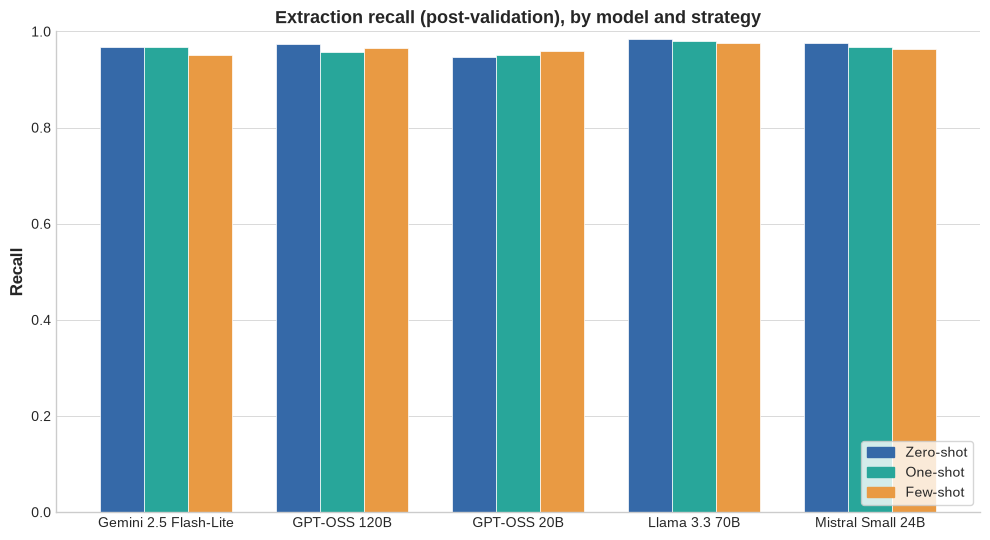

Saved: eval_outputs/extraction_recall_by_model_strategy.png


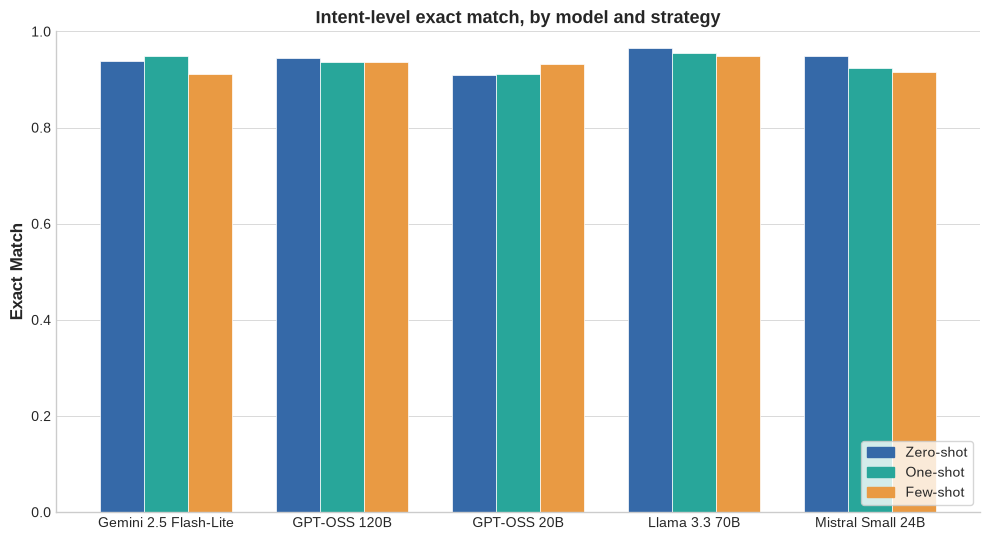

Saved: eval_outputs/exact_match_by_model_strategy.png


In [12]:
def grouped_bar_by_model_strategy(data, title, ylabel, filename, ylim=(0, 1)):
    """data: index=model (MODEL_ORDER), columns=strategy (STRATEGY_ORDER)."""
    fig, ax = plt.subplots(figsize=(10, 5.5))
    plot_df = data.rename(index=MODEL_LABELS)
    plot_df.plot.bar(ax=ax, color=[STRATEGY_COLORS[s] for s in STRATEGY_ORDER], width=0.75,
                      edgecolor="white", linewidth=0.5, legend=False)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylabel(ylabel, fontsize=12, fontweight="bold")
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.tick_params(axis="x", labelrotation=0, labelsize=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", color="#d9d9d9", linewidth=0.7)
    ax.grid(axis="x", visible=False)
    handles = [plt.Rectangle((0, 0), 1, 1, color=STRATEGY_COLORS[s]) for s in STRATEGY_ORDER]
    ax.legend(handles, [STRATEGY_LABELS[s] for s in STRATEGY_ORDER], loc="lower right", frameon=True, fontsize=10)
    fig.tight_layout()
    path = OUT_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: eval_outputs/{path.name}")


grouped_bar_by_model_strategy(
    ext_prf["recall"].unstack("strategy").reindex(MODEL_ORDER),
    "Extraction recall (post-validation), by model and strategy", "Recall",
    "extraction_recall_by_model_strategy.png",
)
grouped_bar_by_model_strategy(
    em["exact_match_raw"].unstack("strategy").reindex(MODEL_ORDER),
    "Intent-level exact match, by model and strategy", "Exact Match",
    "exact_match_by_model_strategy.png",
)

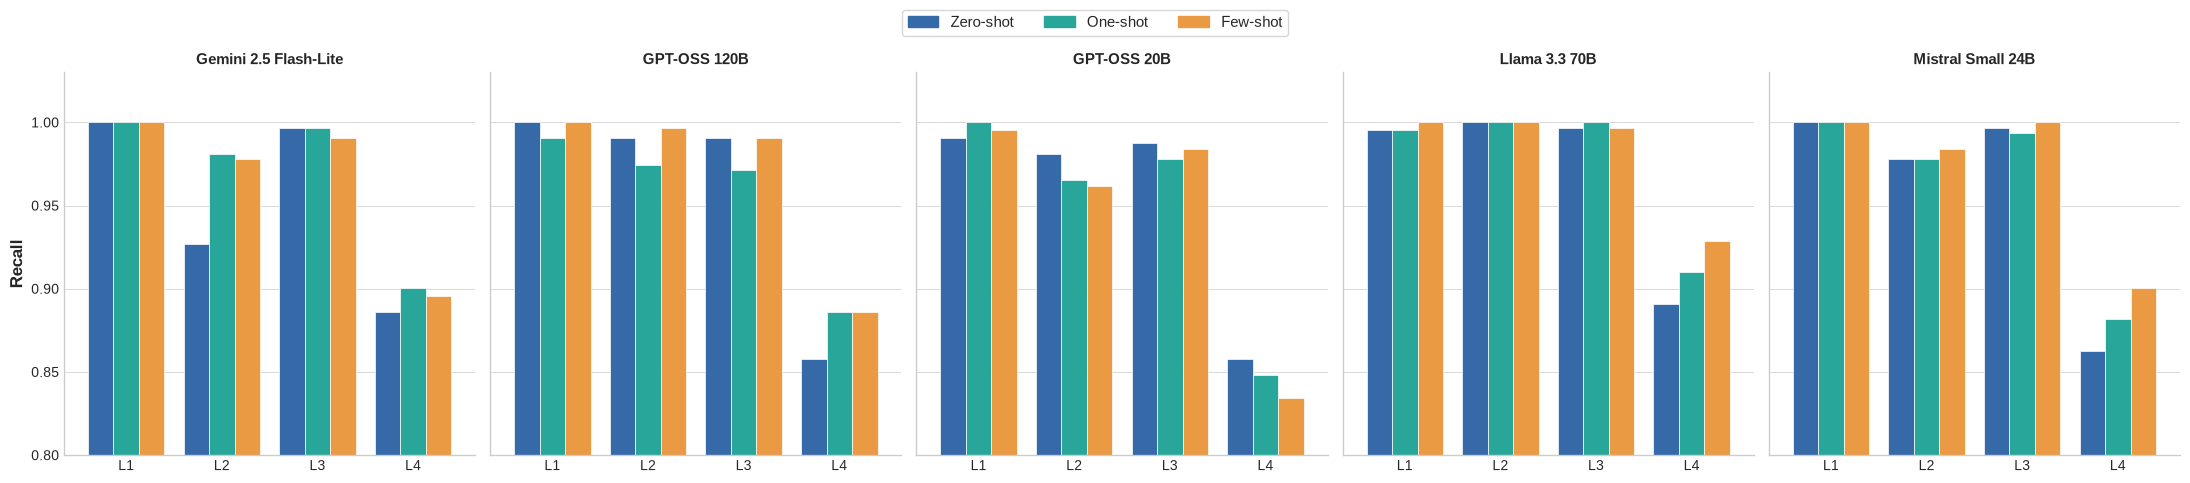

Saved: eval_outputs/recall_by_level_faceted_by_model.png


In [13]:
# Recall by level, faceted by model (5 small multiples; x=level, bars
# grouped by strategy) -- full grid, no collapsing.
fig, axes = plt.subplots(1, 5, figsize=(22, 4.5), sharey=True)
for ax, model in zip(axes, MODEL_ORDER):
    sub = recall_by_level_full.loc[model].reindex(STRATEGY_ORDER)
    sub.columns = [f"L{lvl}" for lvl in sub.columns]
    sub.T.plot.bar(ax=ax, color=[STRATEGY_COLORS[s] for s in STRATEGY_ORDER], width=0.8,
                    edgecolor="white", linewidth=0.5, legend=False)
    ax.set_title(MODEL_LABELS[model], fontsize=11, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylim(0.80, 1.03)
    ax.tick_params(axis="x", labelrotation=0, labelsize=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="y", color="#d9d9d9", linewidth=0.7)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Recall", fontsize=12, fontweight="bold")
handles = [plt.Rectangle((0, 0), 1, 1, color=STRATEGY_COLORS[s]) for s in STRATEGY_ORDER]
fig.legend(handles, [STRATEGY_LABELS[s] for s in STRATEGY_ORDER], loc="upper center",
           bbox_to_anchor=(0.5, 1.08), ncol=3, frameon=True, fontsize=11)
fig.tight_layout()
path = OUT_DIR / "recall_by_level_faceted_by_model.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: eval_outputs/{path.name}")

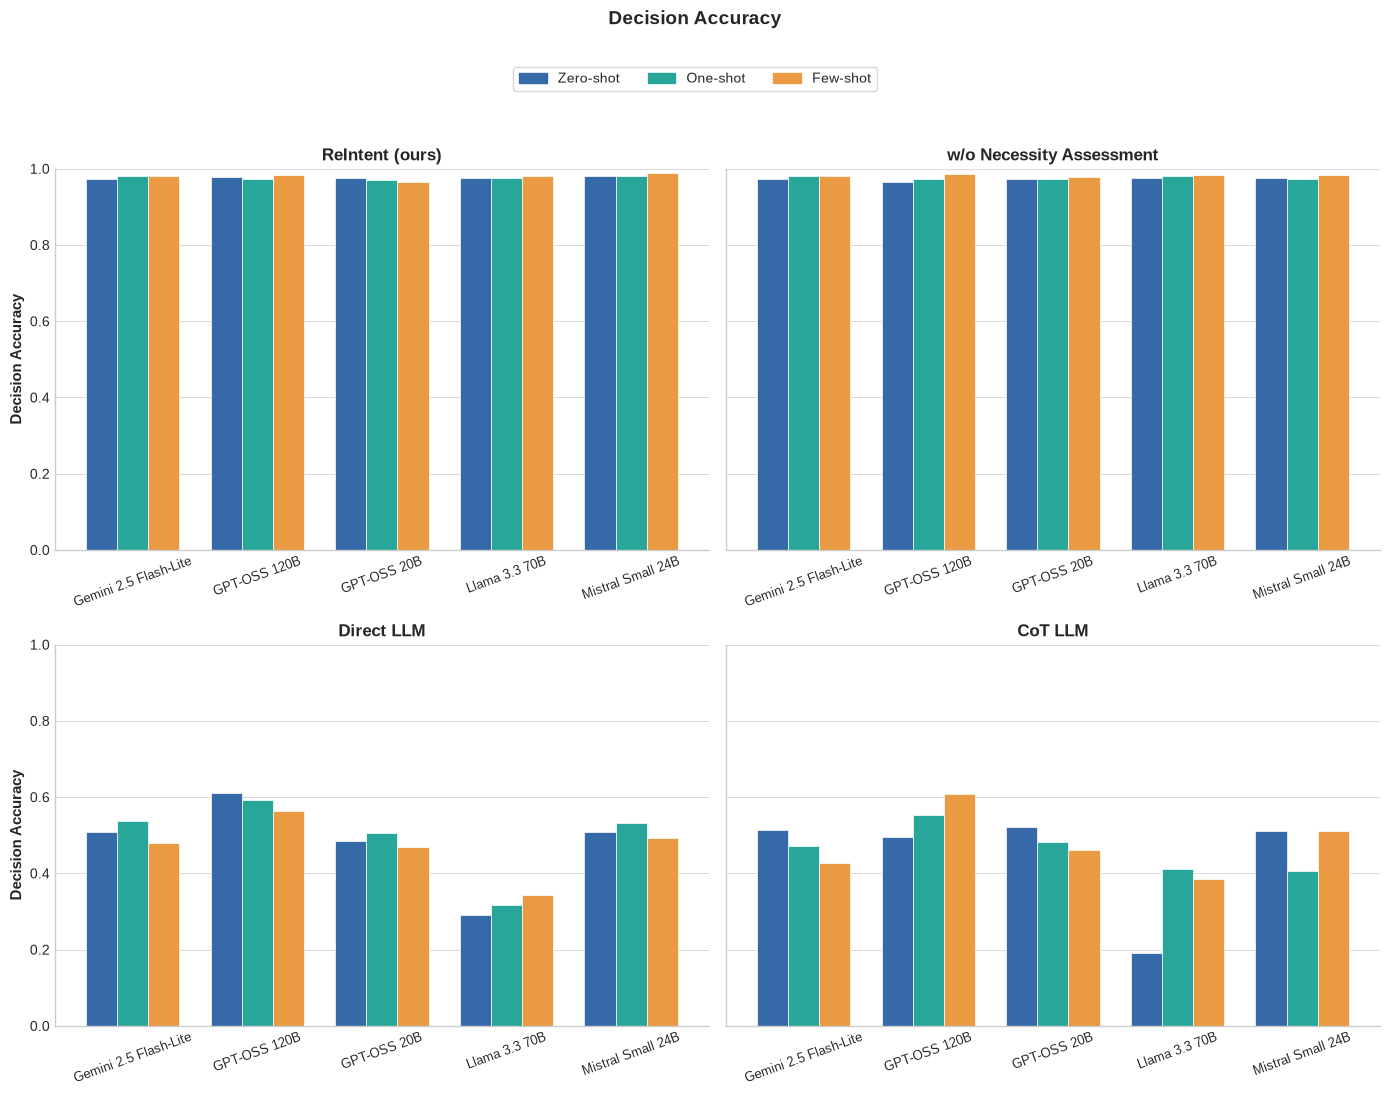

Saved: eval_outputs/e2e_decision_accuracy.png


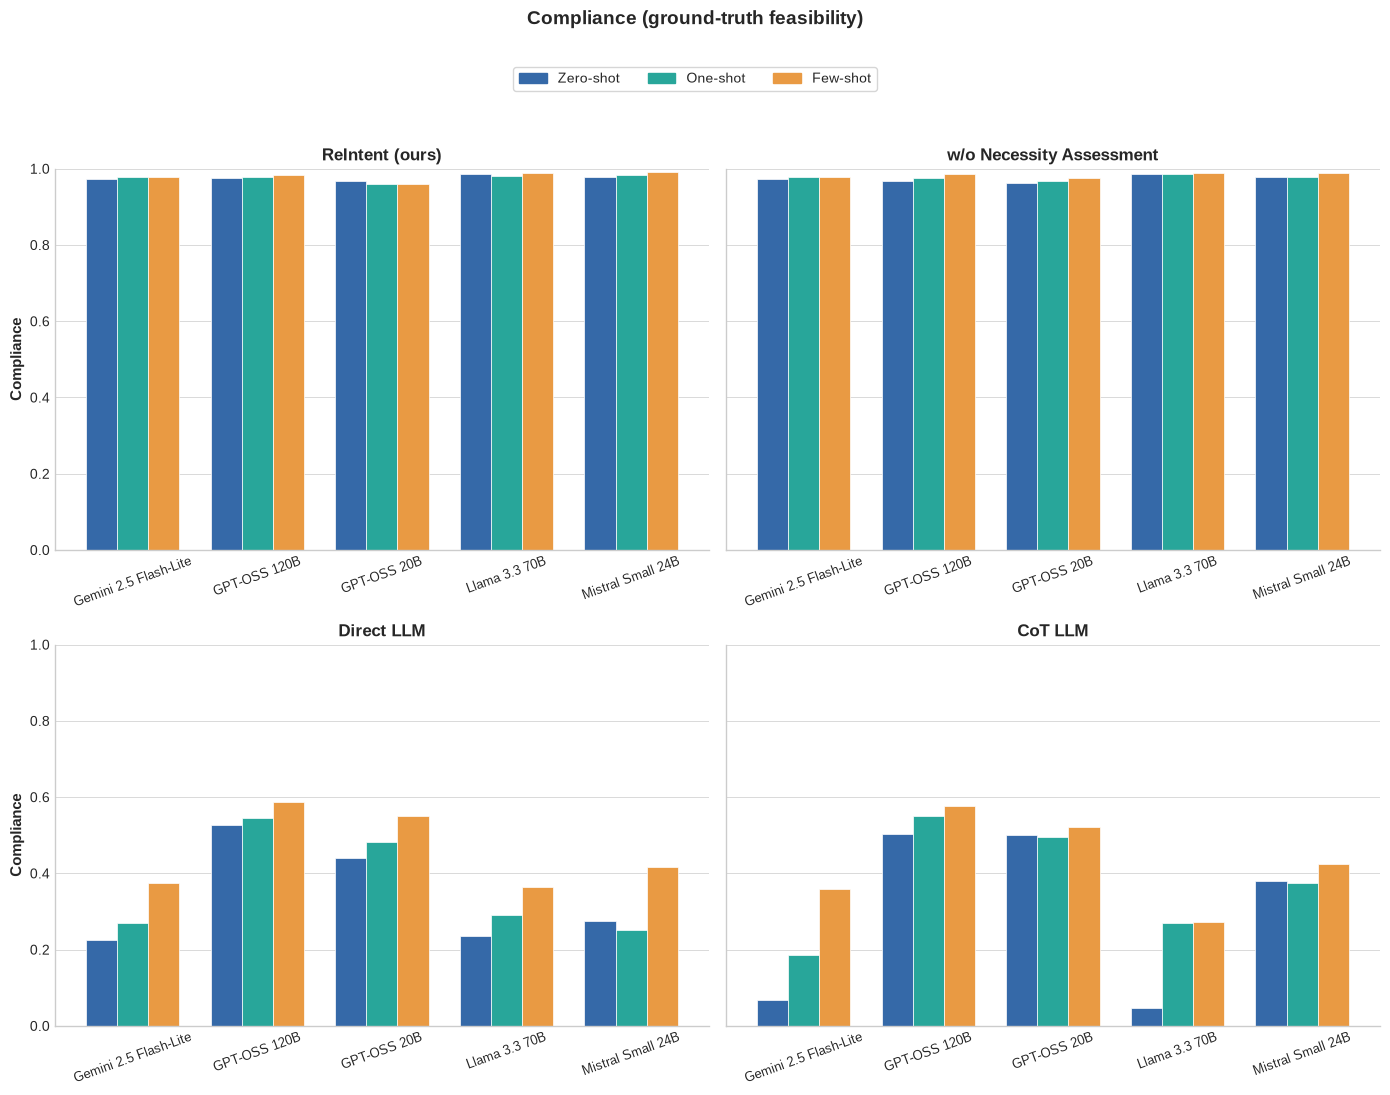

Saved: eval_outputs/e2e_compliance.png


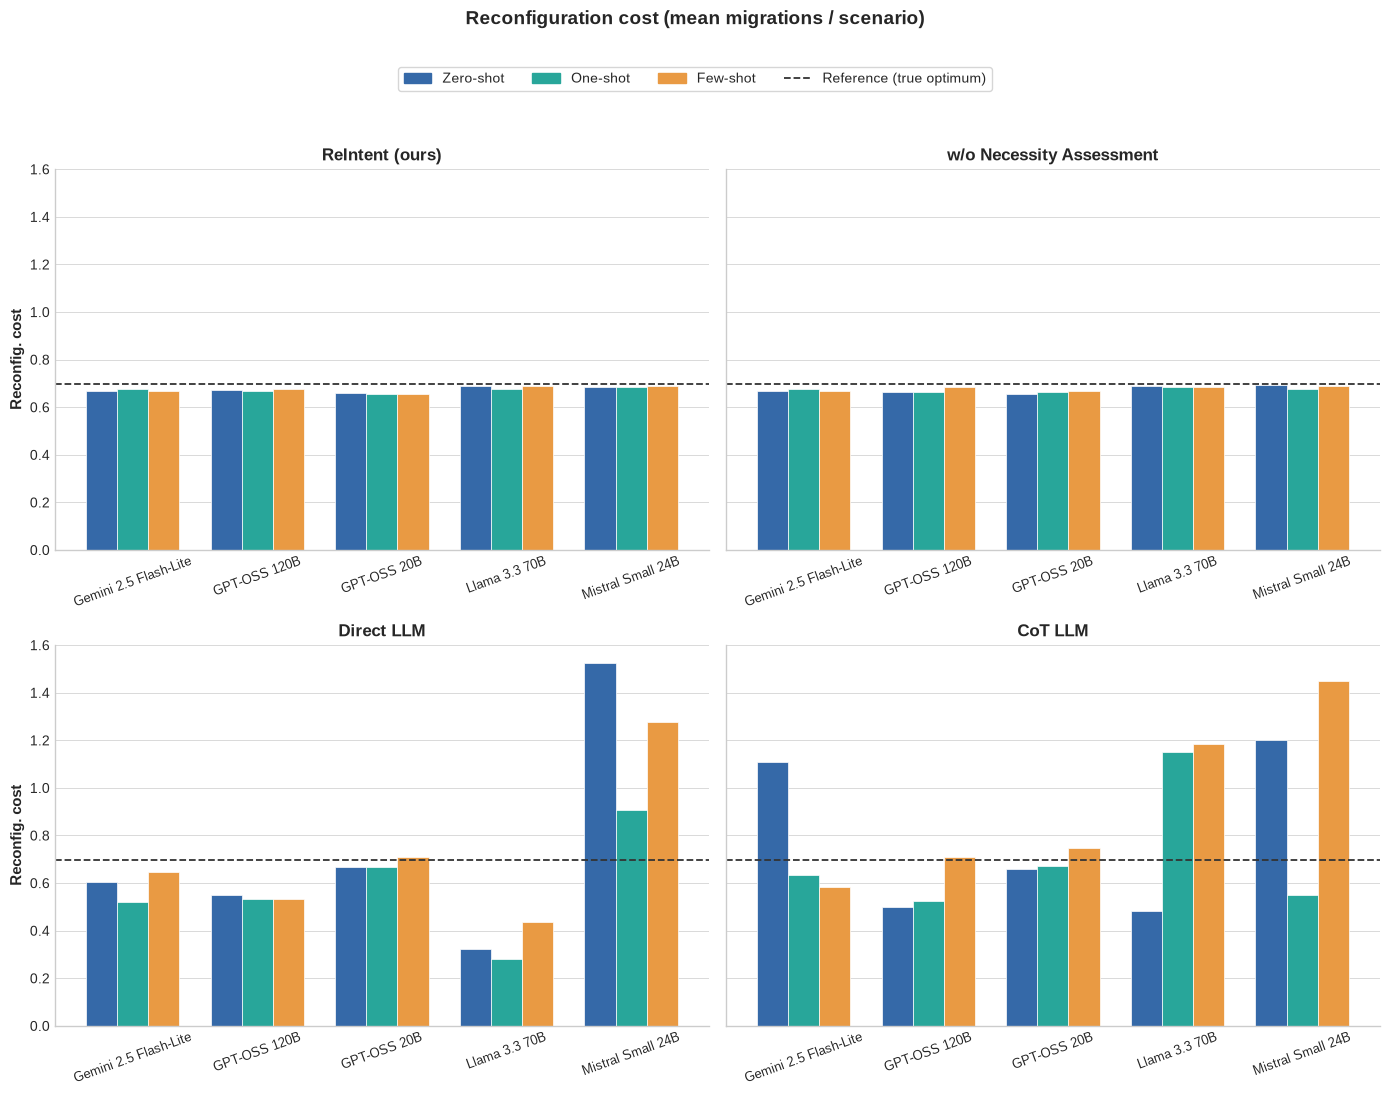

Saved: eval_outputs/e2e_reconfig_cost.png


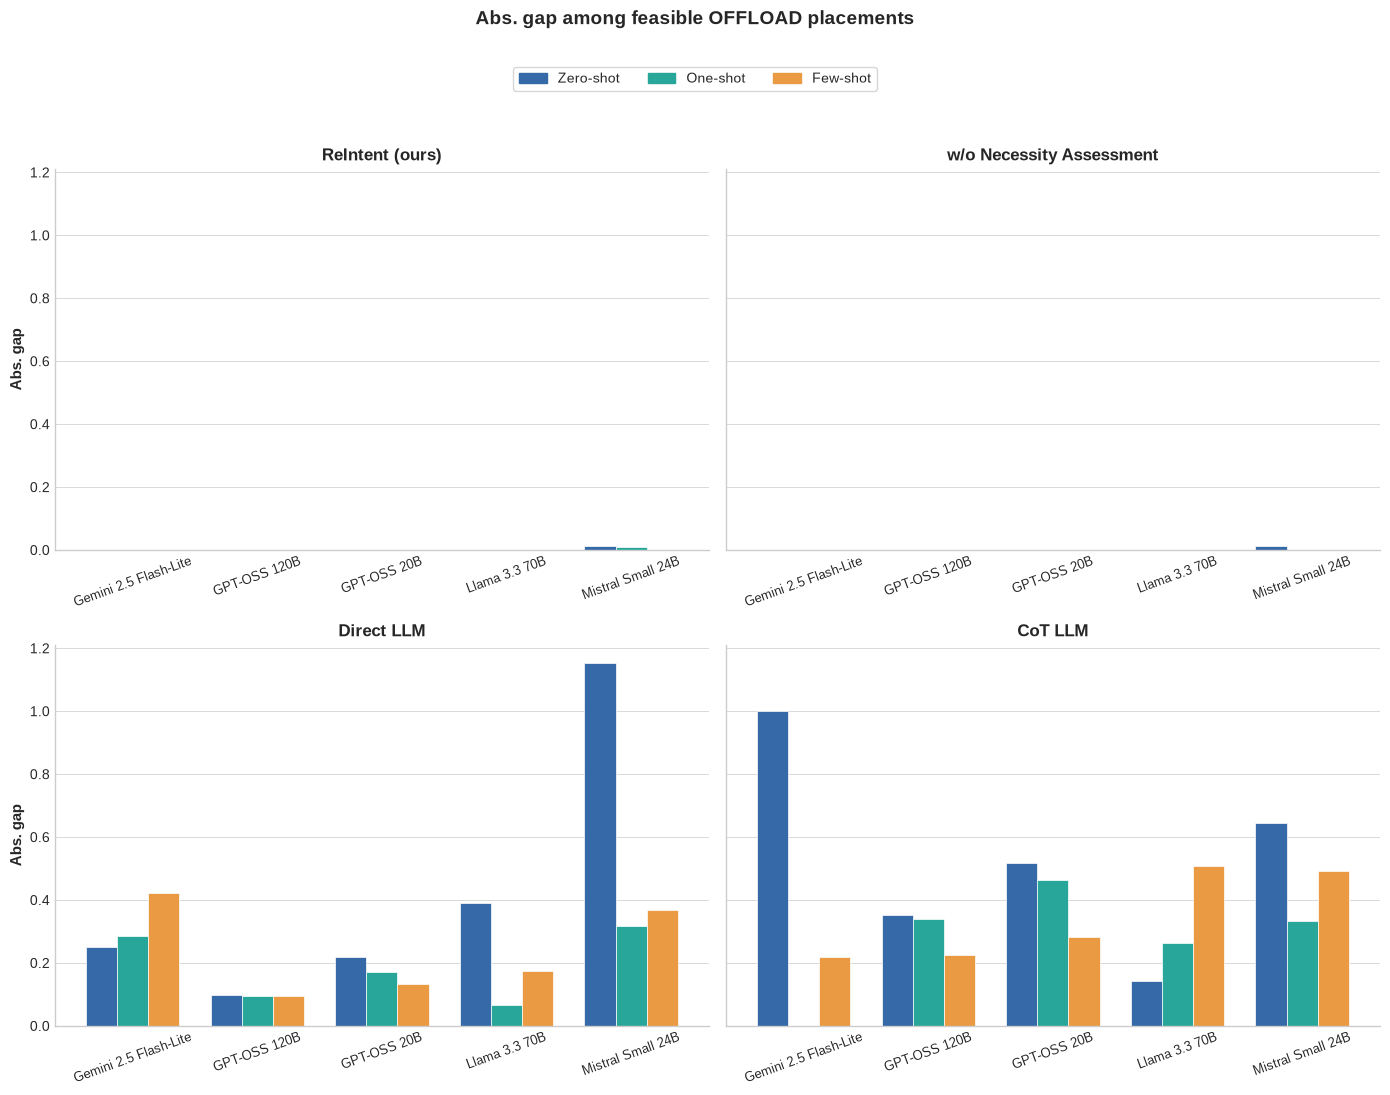

Saved: eval_outputs/e2e_abs_gap.png


In [14]:
def e2e_metric_figure(series, title, ylabel, filename, ylim=(0, 1), ref_line=None):
    """One small multiple per approach (2x2), x=model, bars grouped by strategy."""
    fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharey=True)
    for ax, approach in zip(axes.flat, APPROACH_ORDER):
        data = series.loc[approach].unstack("strategy").reindex(MODEL_ORDER)[STRATEGY_ORDER]
        plot_df = data.rename(index=MODEL_LABELS)
        plot_df.plot.bar(ax=ax, color=[STRATEGY_COLORS[s] for s in STRATEGY_ORDER], width=0.75,
                          edgecolor="white", linewidth=0.5, legend=False)
        ax.set_title(APPROACH_LABELS[approach], fontsize=12, fontweight="bold")
        ax.set_xlabel("")
        if ylim is not None:
            ax.set_ylim(*ylim)
        ax.tick_params(axis="x", labelrotation=20, labelsize=9)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.grid(axis="y", color="#d9d9d9", linewidth=0.7)
        ax.grid(axis="x", visible=False)
        if ref_line is not None:
            ax.axhline(ref_line, color="#333333", linestyle="--", linewidth=1.3)
    for ax in axes[:, 0]:
        ax.set_ylabel(ylabel, fontsize=11, fontweight="bold")
    handles = [plt.Rectangle((0, 0), 1, 1, color=STRATEGY_COLORS[s]) for s in STRATEGY_ORDER]
    labels = [STRATEGY_LABELS[s] for s in STRATEGY_ORDER]
    if ref_line is not None:
        handles.append(plt.Line2D([0], [0], color="#333333", linestyle="--", linewidth=1.3))
        labels.append("Reference (true optimum)")
    fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 1.04), ncol=len(labels), frameon=True, fontsize=10)
    fig.suptitle(title, fontsize=14, fontweight="bold", y=1.09)
    fig.tight_layout()
    path = OUT_DIR / filename
    fig.savefig(path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: eval_outputs/{path.name}")


e2e_metric_figure(decision_accuracy, "Decision Accuracy", "Decision Accuracy",
                   "e2e_decision_accuracy.png", ylim=(0, 1))
e2e_metric_figure(compliance, "Compliance (ground-truth feasibility)", "Compliance",
                   "e2e_compliance.png", ylim=(0, 1))
e2e_metric_figure(reconfig_cost, "Reconfiguration cost (mean migrations / scenario)", "Reconfig. cost",
                   "e2e_reconfig_cost.png", ylim=None, ref_line=ref_mean_reconfig_cost)
e2e_metric_figure(abs_gap, "Abs. gap among feasible OFFLOAD placements", "Abs. gap",
                   "e2e_abs_gap.png", ylim=None)

## Part 4 -- Best-strategy-per-model views (paper headline figures)

For each model, one prompting strategy is selected by extraction EM (Part 1)
and reused across extraction and every end-to-end approach -- a condensed,
"best shot per model" companion to the full grid above, matching the
figures/tables actually used in the paper.

In [15]:
BEST_STRATEGY = {model: em["exact_match_raw"].loc[model].idxmax() for model in MODEL_ORDER}
print("Best strategy per model (by extraction EM):")
for model in MODEL_ORDER:
    print(f"  {model}: {BEST_STRATEGY[model]}")

Best strategy per model (by extraction EM):
  gemini-2.5-flash-lite: one_shot
  gpt-oss-120b: few_shot
  gpt-oss-20b: zero_shot
  llama-3.3-70b: few_shot
  mistral-small-3.2-24b: few_shot


=== Recall by level, one row per model (its own best strategy) ===


level,1,2,3,4
model,,,,
gemini-2.5-flash-lite,1.0000,0.9810,0.9968,0.9005
gpt-oss-120b,1.0000,0.9968,0.9905,0.8863
gpt-oss-20b,0.9905,0.9810,0.9874,0.8578
llama-3.3-70b,1.0000,1.0000,0.9968,0.9289
mistral-small-3.2-24b,1.0000,0.9841,1.0000,0.9005


Saved: eval_outputs/recall_by_level_all_models.csv


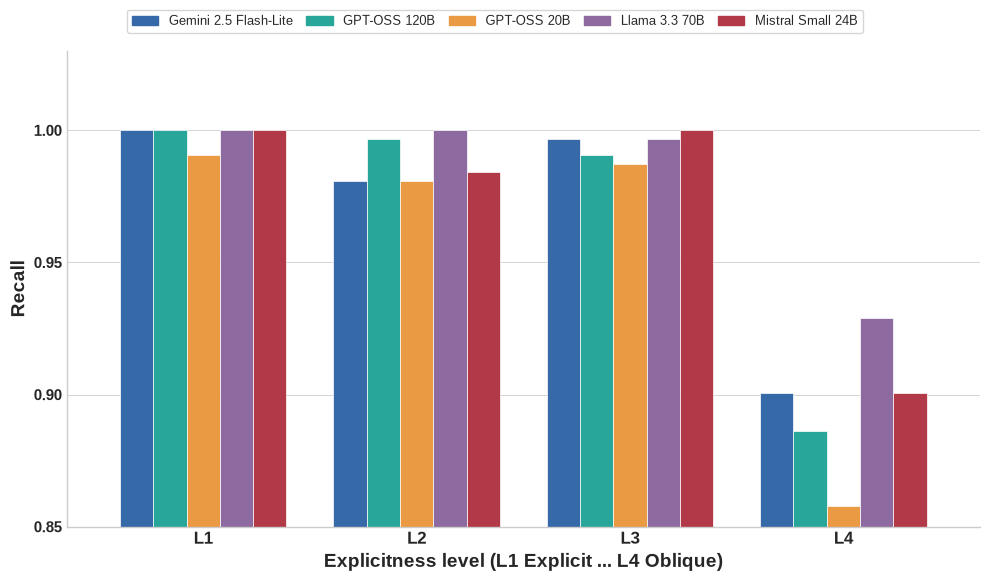

Saved: eval_outputs/recall_by_level_all_models.png


In [16]:
recall_by_level_all_models = pd.DataFrame({
    model: recall_by_level_full.loc[(model, BEST_STRATEGY[model])] for model in MODEL_ORDER
}).T
recall_by_level_all_models.index.name = "model"
print("=== Recall by level, one row per model (its own best strategy) ===")
display(recall_by_level_all_models.round(4))
recall_by_level_all_models.to_csv(OUT_DIR / "recall_by_level_all_models.csv")
print("Saved: eval_outputs/recall_by_level_all_models.csv")

MODEL_COLORS = {
    "gemini-2.5-flash-lite": "#3569A8", "gpt-oss-120b": "#28A69A", "gpt-oss-20b": "#E99A43",
    "llama-3.3-70b": "#8D6A9F", "mistral-small-3.2-24b": "#B23A48",
}
plot_df = recall_by_level_all_models.rename(index=MODEL_LABELS)
plot_df.columns = [f"L{lvl}" for lvl in plot_df.columns]
plot_df = plot_df.T

fig, ax = plt.subplots(figsize=(10, 5.5))
plot_df.plot.bar(ax=ax, color=[MODEL_COLORS[m] for m in MODEL_ORDER], width=0.78,
                  edgecolor="white", linewidth=0.5, legend=False)
ax.set_xlabel("Explicitness level (L1 Explicit ... L4 Oblique)", fontsize=14, fontweight="bold")
ax.set_ylabel("Recall", fontsize=14, fontweight="bold")
ax.set_ylim(0.85, 1.03)
ax.set_yticks([0.85, 0.90, 0.95, 1.00])
ax.tick_params(axis="x", labelrotation=0, labelsize=12)
ax.tick_params(axis="y", labelsize=11)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")
ax.grid(axis="y", color="#d5d5d5", linewidth=0.7)
ax.grid(axis="x", visible=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
handles = [plt.Rectangle((0, 0), 1, 1, color=MODEL_COLORS[m]) for m in MODEL_ORDER]
fig.legend(handles, [MODEL_LABELS[m] for m in MODEL_ORDER], loc="upper center",
           bbox_to_anchor=(0.5, 1.06), ncol=5, frameon=True, fontsize=9.5, columnspacing=1.0)
fig.tight_layout()
path = OUT_DIR / "recall_by_level_all_models.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: eval_outputs/{path.name}")

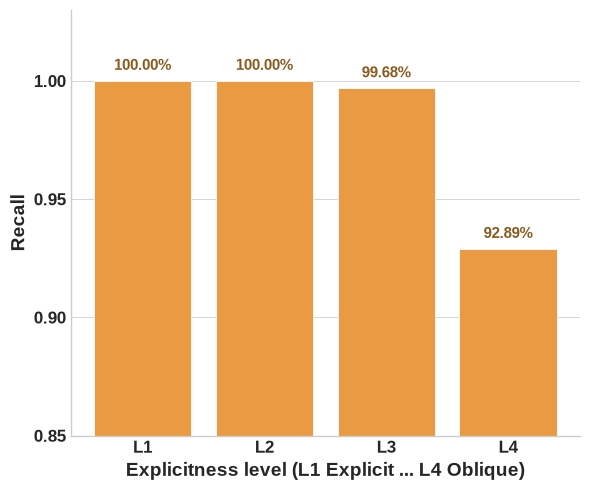

Saved: eval_outputs/recall_by_level_llama_fewshot.png (strategy: few_shot)


In [17]:
# Llama alone, at its own best strategy -- the paper's Fig. 2.
llama_strategy = BEST_STRATEGY["llama-3.3-70b"]
recall_llama = recall_by_level_full.loc[("llama-3.3-70b", llama_strategy)]
level_labels = [f"L{lvl}" for lvl in recall_llama.index]

RECALL_COLOR = "#E99A43"
fig, ax = plt.subplots(figsize=(6, 5))
bars = ax.bar(level_labels, recall_llama.values, color=RECALL_COLOR, edgecolor="white", linewidth=0.6)
for rect, y in zip(bars, recall_llama.values):
    ax.annotate(f"{y * 100:.2f}%", (rect.get_x() + rect.get_width() / 2, y), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=11, color="#8a5a1e", fontweight="bold")
ax.set_xlabel("Explicitness level (L1 Explicit ... L4 Oblique)", fontsize=14, fontweight="bold")
ax.set_ylabel("Recall", fontsize=14, fontweight="bold")
ax.set_ylim(0.85, 1.03)
ax.set_yticks([0.85, 0.90, 0.95, 1.00])
ax.tick_params(axis="both", labelsize=12)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")
ax.grid(axis="y", color="#d5d5d5", linewidth=0.7)
ax.grid(axis="x", visible=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
path = OUT_DIR / "recall_by_level_llama_fewshot.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: eval_outputs/{path.name} (strategy: {llama_strategy})")

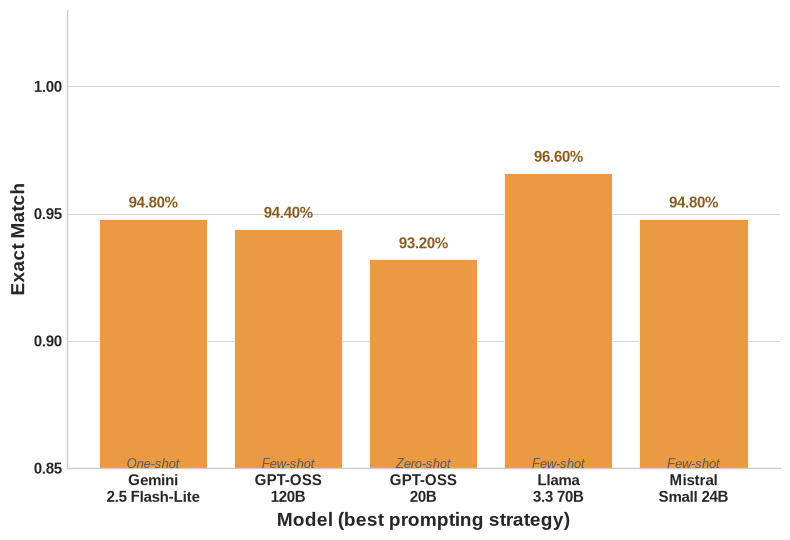

Saved: eval_outputs/exact_match_by_model.png


In [18]:
# Intent-level exact match per model, each at its own best strategy.
em_best = pd.Series({model: em["exact_match_raw"].loc[(model, BEST_STRATEGY[model])] for model in MODEL_ORDER})
labels = [MODEL_LABELS[m].replace(" ", "\n", 1) for m in MODEL_ORDER]

fig, ax = plt.subplots(figsize=(8, 5.5))
bars = ax.bar(labels, em_best.values, color=RECALL_COLOR, edgecolor="white", linewidth=0.6)
for rect, y, model in zip(bars, em_best.values, MODEL_ORDER):
    ax.annotate(f"{y * 100:.2f}%", (rect.get_x() + rect.get_width() / 2, y), textcoords="offset points",
                xytext=(0, 8), ha="center", fontsize=11, color="#8a5a1e", fontweight="bold")
    ax.annotate(STRATEGY_LABELS[BEST_STRATEGY[model]], (rect.get_x() + rect.get_width() / 2, 0.85),
                ha="center", fontsize=9.5, color="#5a5a5a", style="italic")
ax.set_xlabel("Model (best prompting strategy)", fontsize=14, fontweight="bold")
ax.set_ylabel("Exact Match", fontsize=14, fontweight="bold")
ax.set_ylim(0.85, 1.03)
ax.set_yticks([0.85, 0.90, 0.95, 1.00])
ax.tick_params(axis="both", labelsize=11)
for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight("bold")
ax.grid(axis="y", color="#d5d5d5", linewidth=0.7)
ax.grid(axis="x", visible=False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
fig.tight_layout()
path = OUT_DIR / "exact_match_by_model.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: eval_outputs/{path.name}")

In [19]:
# Cost table (time/tokens) and abs. gap, pipeline/direct/cot, each model at its own best strategy.
HEADLINE_APPROACHES = ["pipeline", "direct", "cot"]
rows = []
for model in MODEL_ORDER:
    strat = BEST_STRATEGY[model]
    for approach in HEADLINE_APPROACHES:
        row = e2e_summary.loc[(approach, model, strat)]
        rows.append({"model": model, "approach": approach, "time_s": round(row["time_s"], 2),
                     "tokens": round(row["tokens"], 0)})
cost_table = pd.DataFrame(rows)
print("=== Cost (time/tokens), each model at its own best strategy ===")
display(cost_table)
cost_table.to_csv(OUT_DIR / "cost_table.csv", index=False)
with open(OUT_DIR / "cost_table.md", "w") as f:
    f.write("| Model | Approach | Time (s) | Tokens |\n|---|---|---|---|\n")
    for _, r in cost_table.iterrows():
        f.write(f"| {r['model']} | {APPROACH_LABELS[r['approach']]} | {r['time_s']:.2f} | {r['tokens']:.0f} |\n")
print("Saved: eval_outputs/cost_table.csv, eval_outputs/cost_table.md")

abs_gap_table = pd.DataFrame({
    approach: [e2e_summary.loc[(approach, model, BEST_STRATEGY[model]), "abs_gap_among_feasible"] for model in MODEL_ORDER]
    for approach in HEADLINE_APPROACHES
}, index=MODEL_ORDER)
abs_gap_table.index.name = "model"
print("=== Abs. gap among feasible OFFLOAD placements, each model at its own best strategy ===")
display(abs_gap_table.round(4))
abs_gap_table.round(4).to_csv(OUT_DIR / "abs_gap.csv")
print("Saved: eval_outputs/abs_gap.csv")

=== Cost (time/tokens), each model at its own best strategy ===


,model,approach,time_s,tokens
0,gemini-2.5-flash-lite,pipeline,1.78,3665.0
1,gemini-2.5-flash-lite,direct,7.11,6836.0
2,gemini-2.5-flash-lite,cot,8.92,8244.0
3,gpt-oss-120b,pipeline,5.14,5424.0
4,gpt-oss-120b,direct,5.29,7387.0
5,gpt-oss-120b,cot,9.12,10223.0
6,gpt-oss-20b,pipeline,3.56,5110.0
7,gpt-oss-20b,direct,7.46,4438.0
8,gpt-oss-20b,cot,14.30,6465.0
9,llama-3.3-70b,pipeline,6.66,4203.0


Saved: eval_outputs/cost_table.csv, eval_outputs/cost_table.md
=== Abs. gap among feasible OFFLOAD placements, each model at its own best strategy ===


,pipeline,direct,cot
model,,,
gemini-2.5-flash-lite,0.0,0.2857,0.0000
gpt-oss-120b,0.0,0.0952,0.2250
gpt-oss-20b,0.0,0.2195,0.5185
llama-3.3-70b,0.0,0.1731,0.5088
mistral-small-3.2-24b,0.0,0.3671,0.4935


Saved: eval_outputs/abs_gap.csv


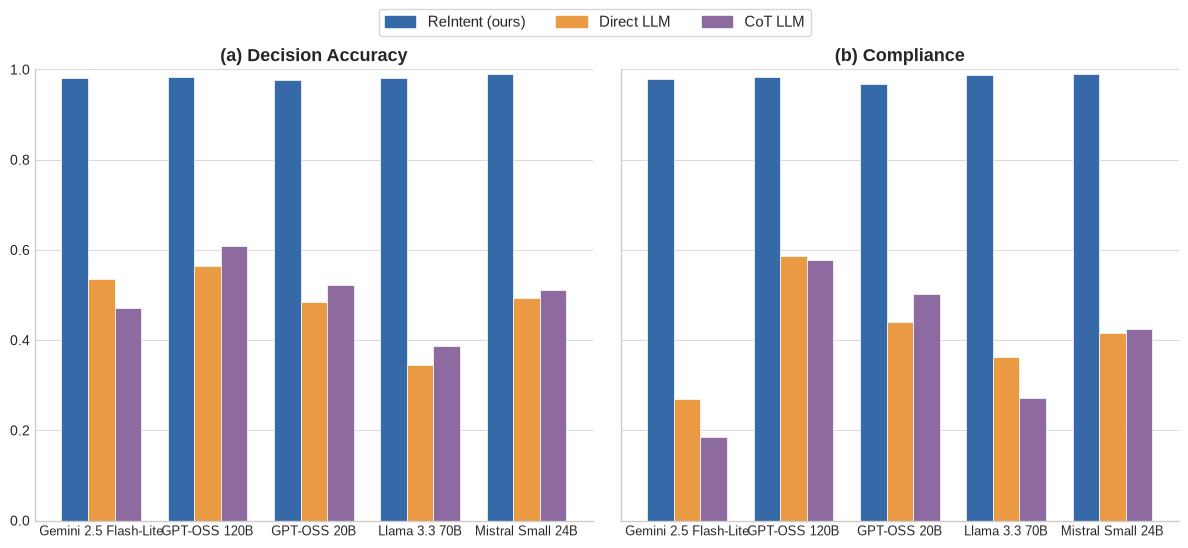

Saved: eval_outputs/figure_decision_compliance.png


In [20]:
# (a)/(b) figure: Decision Accuracy + Compliance, pipeline/direct/cot, each
# model at its own best strategy -- Option B from the paper discussion.
APPROACH_COLORS_3 = {"pipeline": "#3569A8", "direct": "#E99A43", "cot": "#8D6A9F"}
APPROACH_LABELS_3 = {"pipeline": "ReIntent (ours)", "direct": "Direct LLM", "cot": "CoT LLM"}

decision_acc_best = pd.DataFrame({
    approach: [e2e_summary.loc[(approach, model, BEST_STRATEGY[model]), "decision_accuracy"] for model in MODEL_ORDER]
    for approach in HEADLINE_APPROACHES
}, index=MODEL_ORDER)
compliance_best = pd.DataFrame({
    approach: [e2e_summary.loc[(approach, model, BEST_STRATEGY[model]), "compliance"] for model in MODEL_ORDER]
    for approach in HEADLINE_APPROACHES
}, index=MODEL_ORDER)

fig, axes = plt.subplots(1, 2, figsize=(12, 5.2), sharey=True)
for ax, data, letter, title in [(axes[0], decision_acc_best, "(a)", "Decision Accuracy"),
                                 (axes[1], compliance_best, "(b)", "Compliance")]:
    plot_df = data.rename(index=MODEL_LABELS)
    plot_df.plot.bar(ax=ax, color=[APPROACH_COLORS_3[a] for a in HEADLINE_APPROACHES], width=0.75,
                      edgecolor="white", linewidth=0.5, legend=False)
    ax.set_title(f"{letter} {title}", fontsize=13, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", labelrotation=0, labelsize=9)
    ax.tick_params(axis="y", labelsize=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", color="#d9d9d9", linewidth=0.7)
handles = [plt.Rectangle((0, 0), 1, 1, color=APPROACH_COLORS_3[a]) for a in HEADLINE_APPROACHES]
fig.legend(handles, [APPROACH_LABELS_3[a] for a in HEADLINE_APPROACHES], loc="upper center",
           bbox_to_anchor=(0.5, 1.06), ncol=3, frameon=True, fontsize=11)
fig.tight_layout()
path = OUT_DIR / "figure_decision_compliance.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: eval_outputs/{path.name}")

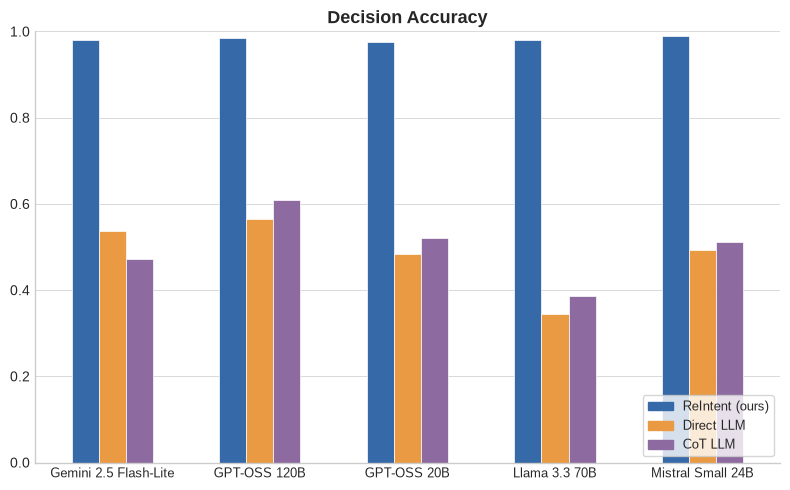

Saved: eval_outputs/figure_decision_accuracy_thin.png


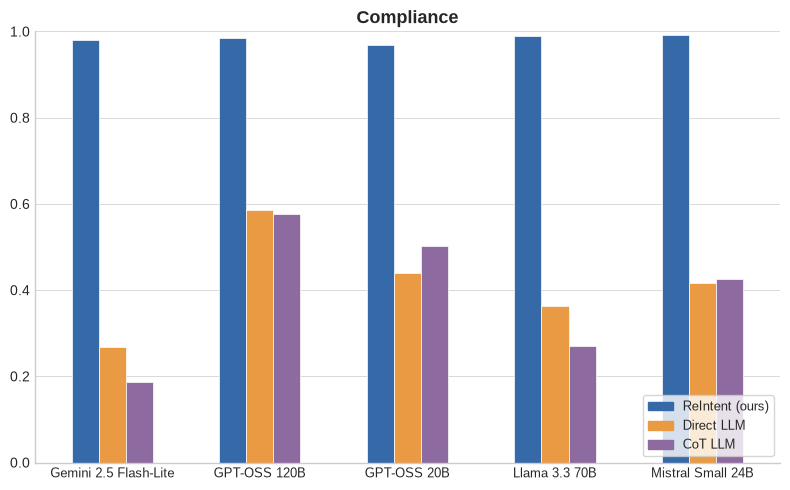

Saved: eval_outputs/figure_compliance_thin.png


In [21]:
# Same two metrics, as separate thin-bar single-panel figures.
for data, title, fname in [(decision_acc_best, "Decision Accuracy", "figure_decision_accuracy_thin.png"),
                            (compliance_best, "Compliance", "figure_compliance_thin.png")]:
    plot_df = data.rename(index=MODEL_LABELS)
    fig2, ax = plt.subplots(figsize=(8, 5))
    plot_df.plot.bar(ax=ax, color=[APPROACH_COLORS_3[a] for a in HEADLINE_APPROACHES], width=0.55,
                      edgecolor="white", linewidth=0.5, legend=False)
    ax.set_title(title, fontsize=13, fontweight="bold")
    ax.set_xlabel("")
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", labelrotation=0, labelsize=9)
    ax.tick_params(axis="y", labelsize=10)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", color="#d9d9d9", linewidth=0.7)
    handles2 = [plt.Rectangle((0, 0), 1, 1, color=APPROACH_COLORS_3[a]) for a in HEADLINE_APPROACHES]
    ax.legend(handles2, [APPROACH_LABELS_3[a] for a in HEADLINE_APPROACHES], loc="lower right", frameon=True, fontsize=9)
    fig2.tight_layout()
    thin_path = OUT_DIR / fname
    fig2.savefig(thin_path, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Saved: eval_outputs/{thin_path.name}")

## Part 5 -- Under-/over-triggering breakdown

Why reconfiguration cost alone is not a quality signal (see the paper's
discussion of Table 2/3): a value below the reference optimum can come
from **under-triggering** (no migration proposed on a scenario that
actually needs one), and a value above it from **over-triggering**
(a migration proposed on a scenario that needs none). Both rates below,
full grid -- not just the two cases singled out in the text.

In [22]:
offload_gt = df_e2e[df_e2e["gt_decision"] == "OFFLOAD"]
stay_gt = df_e2e[df_e2e["gt_decision"] == "STAY"]

under_trigger_rate = offload_gt.groupby(["approach", "model", "strategy"])["n_moved_pred"].apply(lambda s: (s == 0).mean())
over_trigger_rate = stay_gt.groupby(["approach", "model", "strategy"])["n_moved_pred"].apply(lambda s: (s > 0).mean())

trigger_summary = pd.DataFrame({
    "under_trigger_rate": under_trigger_rate,  # among OFFLOAD gt: no migration proposed
    "over_trigger_rate": over_trigger_rate,    # among STAY gt: a migration proposed anyway
}).reindex(MIDX_APPROACH)

print("=== Under-/over-triggering, full grid (approach x model x strategy) ===")
display(trigger_summary.round(4))
trigger_summary.round(4).to_csv(OUT_DIR / "trigger_rates.csv")
print("Saved: eval_outputs/trigger_rates.csv")

# Sanity check against the two cases singled out in the paper text.
llama_strat, mistral_strat = BEST_STRATEGY["llama-3.3-70b"], BEST_STRATEGY["mistral-small-3.2-24b"]
print()
print(f"Llama 3.3 70B Direct ({llama_strat}) under-trigger rate:",
      f"{trigger_summary.loc[('direct', 'llama-3.3-70b', llama_strat), 'under_trigger_rate']:.1%}")
print(f"Mistral Small 3.2 24B CoT ({mistral_strat}) over-trigger rate:",
      f"{trigger_summary.loc[('cot', 'mistral-small-3.2-24b', mistral_strat), 'over_trigger_rate']:.1%}")

=== Under-/over-triggering, full grid (approach x model x strategy) ===


under_trigger_rate  \
approach model                 strategy                        
pipeline gemini-2.5-flash-lite zero_shot              0.0490   
                               one_shot               0.0367   
                               few_shot               0.0408   
         gpt-oss-120b          zero_shot              0.0327   
                               one_shot               0.0408   
                               few_shot               0.0245   
         gpt-oss-20b           zero_shot              0.0449   
                               one_shot               0.0531   
                               few_shot               0.0571   
         llama-3.3-70b         zero_shot              0.0245   
                               one_shot               0.0327   
                               few_shot               0.0204   
         mistral-small-3.2-24b zero_shot              0.0327   
                               one_shot               0.0245   
                               few_shot               0.0163   
ablation gemini-2.5-flash-lite zero_shot              0.0490   
                               one_shot               0.0367   
                               few_shot               0.0408   
         gpt-oss-120b          zero_shot              0.0531   
                               one_shot               0.0408   
                               few_shot               0.0245   
         gpt-oss-20b           zero_shot              0.0490   
                               one_shot               0.0490   
                               few_shot               0.0327   
         llama-3.3-70b         zero_shot              0.0245   
                               one_shot               0.0245   
                               few_shot               0.0204   
         mistral-small-3.2-24b zero_shot              0.0327   
                               one_shot               0.0408   
                               few_shot               0.0163   
direct   gemini-2.5-flash-lite zero_shot              0.3959   
                               one_shot               0.4571   
                               few_shot               0.4122   
         gpt-oss-120b          zero_shot              0.3959   
                               one_shot               0.4122   
                               few_shot               0.4163   
         gpt-oss-20b           zero_shot              0.4694   
                               one_shot               0.4327   
                               few_shot               0.4163   
         llama-3.3-70b         zero_shot              0.7265   
                               one_shot               0.6939   
                               few_shot               0.5592   
         mistral-small-3.2-24b zero_shot              0.1306   
                               one_shot               0.1918   
                               few_shot               0.0980   
cot      gemini-2.5-flash-lite zero_shot              0.0612   
                               one_shot               0.3959   
                               few_shot               0.4122   
         gpt-oss-120b          zero_shot              0.6000   
                               one_shot               0.5184   
                               few_shot               0.3796   
         gpt-oss-20b           zero_shot              0.4898   
                               one_shot               0.5224   
                               few_shot               0.4571   
         llama-3.3-70b         zero_shot              0.6286   
                               one_shot               0.2041   
                               few_shot               0.2531   
         mistral-small-3.2-24b zero_shot              0.1796   
                               one_shot               0.6286   
                               few_shot               0.0653   

                                          over_trigger_rate  
approach mo

Saved: eval_outputs/trigger_rates.csv

Llama 3.3 70B Direct (few_shot) under-trigger rate: 55.9%
Mistral Small 3.2 24B CoT (few_shot) over-trigger rate: 86.3%


## Part 6 -- Figure 3 reproduction: decision accuracy spread across strategies

ReIntent at its own best strategy (one dot, no spread -- ReIntent is not
prompt-sensitive the way a single-shot baseline is) against Direct LLM and
CoT LLM, both shown across all three prompting strategies (one marker per
strategy, a thin bar spanning min->max) -- the real counterpart to the
paper's Fig. 3.

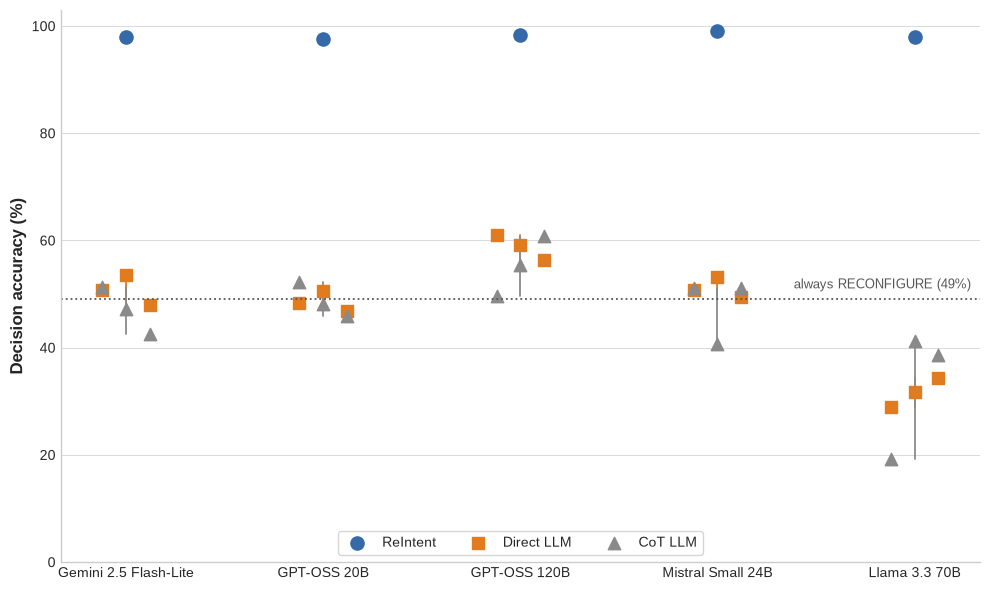

Saved: eval_outputs/figure3_decision_accuracy_range.png


In [23]:
import numpy as np
import matplotlib.transforms

FIG3_MODEL_ORDER = ["gemini-2.5-flash-lite", "gpt-oss-20b", "gpt-oss-120b", "mistral-small-3.2-24b", "llama-3.3-70b"]
JITTER = {"zero_shot": -0.12, "one_shot": 0.0, "few_shot": 0.12}
ALWAYS_OFFLOAD_RATE = (REF_DECISION_LOOKUP == "OFFLOAD").mean()

fig, ax = plt.subplots(figsize=(10, 6))
x = np.arange(len(FIG3_MODEL_ORDER))

for i, model in enumerate(FIG3_MODEL_ORDER):
    # ReIntent: single point, no spread, at this model's own best strategy (same convention as Part 4).
    strat = BEST_STRATEGY[model]
    acc = e2e_summary.loc[("pipeline", model, strat), "decision_accuracy"]
    ax.scatter(i, acc, marker="o", s=90, color="#3569A8", zorder=3,
               label="ReIntent" if i == 0 else None)

    for approach, marker, color in [("direct", "s", "#E07B20"), ("cot", "^", "#8A8A8A")]:
        vals = {s: e2e_summary.loc[(approach, model, s), "decision_accuracy"] for s in STRATEGY_ORDER}
        ax.plot([i, i], [min(vals.values()), max(vals.values())], color=color, linewidth=1.3, zorder=1)
        for s, v in vals.items():
            ax.scatter(i + JITTER[s], v, marker=marker, s=80, color=color, zorder=2,
                       label={"direct": "Direct LLM", "cot": "CoT LLM"}[approach] if i == 0 and s == "one_shot" else None)

ax.axhline(ALWAYS_OFFLOAD_RATE, color="#555555", linestyle=":", linewidth=1.3)
label_trans = matplotlib.transforms.blended_transform_factory(ax.transAxes, ax.transData)
ax.text(0.99, ALWAYS_OFFLOAD_RATE + 0.015, f"always RECONFIGURE ({ALWAYS_OFFLOAD_RATE:.0%})",
        transform=label_trans, fontsize=9, color="#555555", ha="right", va="bottom")

ax.set_xticks(x)
ax.set_xticklabels([MODEL_LABELS[m] for m in FIG3_MODEL_ORDER], fontsize=10)
ax.set_ylabel("Decision accuracy (%)", fontsize=12, fontweight="bold")
ax.set_ylim(0, 1.03)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y * 100:.0f}"))
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#d9d9d9", linewidth=0.7)
ax.grid(axis="x", visible=False)
ax.legend(loc="lower center", ncol=3, frameon=True, fontsize=10)
fig.tight_layout()
path = OUT_DIR / "figure3_decision_accuracy_range.png"
fig.savefig(path, dpi=300, bbox_inches="tight")
plt.show()
print(f"Saved: eval_outputs/{path.name}")